# Import libraries and check the dataset

In [2]:
import os
import torch
import numpy as np
import matplotlib.pyplot as plt

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# Display attached dataset paths
for dirname, _, filenames in os.walk("/kaggle/input"):
    for filename in filenames[:5]:
        print(os.path.join(dirname, filename))

PyTorch version: 2.11.0+cu128
GPU available: True
GPU: Tesla T4
/kaggle/input/datasets/ayush1220/cifar10/cifar10/test/airplane/0001.png
/kaggle/input/datasets/ayush1220/cifar10/cifar10/test/airplane/0002.png
/kaggle/input/datasets/ayush1220/cifar10/cifar10/test/airplane/0003.png
/kaggle/input/datasets/ayush1220/cifar10/cifar10/test/airplane/0004.png
/kaggle/input/datasets/ayush1220/cifar10/cifar10/test/airplane/0005.png
/kaggle/input/datasets/ayush1220/cifar10/cifar10/test/automobile/0001.png
/kaggle/input/datasets/ayush1220/cifar10/cifar10/test/automobile/0002.png
/kaggle/input/datasets/ayush1220/cifar10/cifar10/test/automobile/0003.png
/kaggle/input/datasets/ayush1220/cifar10/cifar10/test/automobile/0004.png
/kaggle/input/datasets/ayush1220/cifar10/cifar10/test/automobile/0005.png
/kaggle/input/datasets/ayush1220/cifar10/cifar10/test/bird/0001.png
/kaggle/input/datasets/ayush1220/cifar10/cifar10/test/bird/0002.png
/kaggle/input/datasets/ayush1220/cifar10/cifar10/test/bird/0003.png
/k

# Data preparation

# Prepare a smaller training dataset

In [12]:
import numpy as np
from torch.utils.data import Subset, DataLoader

np.random.seed(42)

train_indices, test_indices = [], []

for c in range(10):
    train_class = [i for i, (_, y) in enumerate(train_data.samples) if y == c]
    test_class = [i for i, (_, y) in enumerate(test_data.samples) if y == c]

    train_indices.extend(np.random.choice(train_class, 100, replace=False))
    test_indices.extend(np.random.choice(test_class, 10, replace=False))

small_train_data = Subset(train_data, train_indices)
small_test_data = Subset(test_data, test_indices)

train_loader = DataLoader(small_train_data, batch_size=32, shuffle=True, num_workers=2)
test_loader = DataLoader(small_test_data, batch_size=32, shuffle=False, num_workers=2)

print("Training images:", len(small_train_data))
print("Testing images:", len(small_test_data))

Training images: 1000
Testing images: 100


# Pretrained model implementation

In [9]:
import torch.nn as nn
from torchvision import models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
model.fc = nn.Linear(model.fc.in_features, 10)
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.0001)

print("Model: Pretrained ResNet18")
print("Device:", device)
print("Output classes:", model.fc.out_features)

Model: Pretrained ResNet18
Device: cuda
Output classes: 10


# Model training

In [13]:
from tqdm.auto import tqdm

epochs = 3

for epoch in range(epochs):
    model.train()
    total_loss, correct, total = 0, 0, 0

    for images, labels in tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}"):
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)

    print(f"Epoch {epoch+1}: Loss={total_loss/len(train_loader):.4f}, "
          f"Accuracy={100*correct/total:.2f}%")

torch.save(model.state_dict(), "/kaggle/working/resnet18_cifar10.pth")
print("Model saved successfully!")

Epoch 1/3:   0%|          | 0/32 [00:00<?, ?it/s]

Epoch 1: Loss=0.4054, Accuracy=86.30%


Epoch 2/3:   0%|          | 0/32 [00:00<?, ?it/s]

Epoch 2: Loss=0.1030, Accuracy=98.20%


Epoch 3/3:   0%|          | 0/32 [00:00<?, ?it/s]

Epoch 3: Loss=0.0551, Accuracy=99.30%
Model saved successfully!


# Performance evaluation

Test Accuracy: 93.0 %

Classification Report:

              precision    recall  f1-score   support

    airplane       0.91      1.00      0.95        10
  automobile       0.91      1.00      0.95        10
        bird       0.91      1.00      0.95        10
         cat       1.00      0.70      0.82        10
        deer       0.91      1.00      0.95        10
         dog       0.83      1.00      0.91        10
        frog       0.91      1.00      0.95        10
       horse       1.00      0.80      0.89        10
        ship       1.00      0.90      0.95        10
       truck       1.00      0.90      0.95        10

    accuracy                           0.93       100
   macro avg       0.94      0.93      0.93       100
weighted avg       0.94      0.93      0.93       100



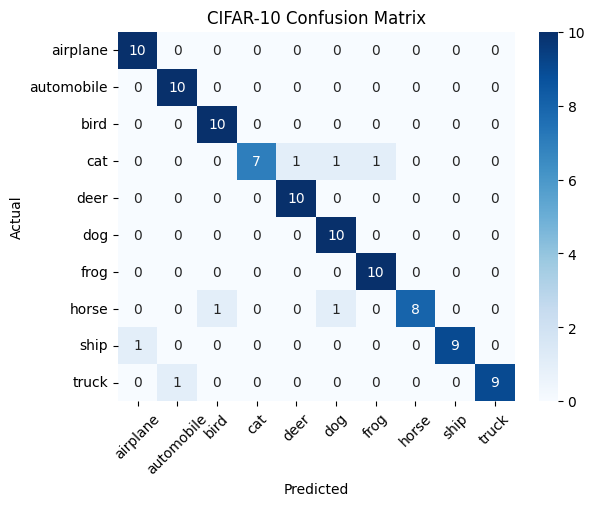

In [14]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import torch

model.eval()
y_true, y_pred = [], []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        predictions = outputs.argmax(1).cpu().numpy()

        y_pred.extend(predictions)
        y_true.extend(labels.numpy())

print("Test Accuracy:", round(accuracy_score(y_true, y_pred) * 100, 2), "%")
print("\nClassification Report:\n")
print(classification_report(y_true, y_pred, target_names=classes, zero_division=0))

cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt="d", xticklabels=classes,
            yticklabels=classes, cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("CIFAR-10 Confusion Matrix")
plt.xticks(rotation=45)
plt.show()

# Result analysis

Test Accuracy: 93.00%
Macro F1-score: 0.928
Weighted F1-score: 0.928
Best class: airplane (F1 = 0.95)
Weakest class: cat (F1 = 0.82)


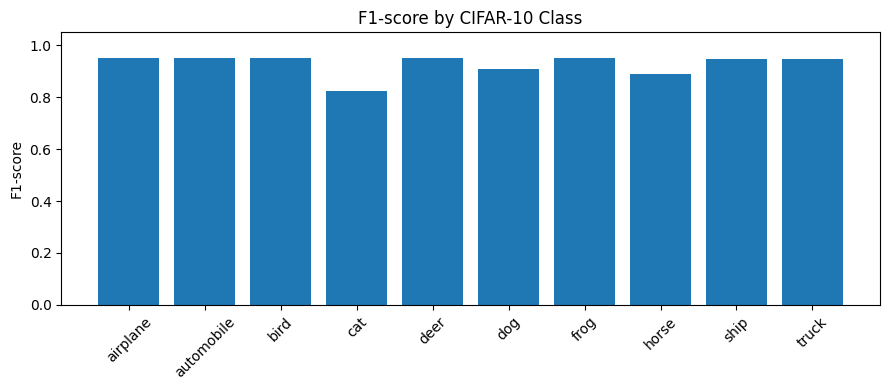

In [15]:
from sklearn.metrics import f1_score
import numpy as np
import matplotlib.pyplot as plt

class_f1 = f1_score(y_true, y_pred, average=None, zero_division=0)

print("Test Accuracy:", f"{accuracy_score(y_true, y_pred)*100:.2f}%")
print("Macro F1-score:", f"{f1_score(y_true, y_pred, average='macro'):.3f}")
print("Weighted F1-score:", f"{f1_score(y_true, y_pred, average='weighted'):.3f}")

print("Best class:", classes[np.argmax(class_f1)],
      f"(F1 = {max(class_f1):.2f})")
print("Weakest class:", classes[np.argmin(class_f1)],
      f"(F1 = {min(class_f1):.2f})")

plt.figure(figsize=(9, 4))
plt.bar(classes, class_f1)
plt.ylabel("F1-score")
plt.title("F1-score by CIFAR-10 Class")
plt.xticks(rotation=45)
plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()